# Last Mile Logistics Auditor: Veridi Logistics
Audit of delivery performance (promised vs actual) and its effect on customer reviews, using the Olist Brazilian e-commerce dataset.

**How to run:** put the Olist CSV files in the same folder as this notebook (in Colab, the upload cell below does this for you). No local paths are used.

**Sections**
1. Schema builder (joins)
2. Delay calculator
3. Geographic view (late % by state)
4. Sentiment correlation
5. Bonus: English product categories
6. Candidate's Choice: promised vs actual lead time
7. Export slim data for the dashboard

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 0. Load the raw data
Expected files (from Kaggle: *olistbr/brazilian-ecommerce*). `order_items` is needed because products are linked to orders through it, and the translation file is needed for the bonus story.

In [2]:
DATA_DIR = Path(".")  # same folder as the notebook

REQUIRED = [
    "olist_orders_dataset.csv",
    "olist_order_reviews_dataset.csv",
    "olist_customers_dataset.csv",
    "olist_products_dataset.csv",
    "olist_order_items_dataset.csv",
    "product_category_name_translation.csv",
]

missing = [f for f in REQUIRED if not (DATA_DIR / f).exists()]
if missing:
    try:
        from google.colab import files  # only exists inside Colab
        print("Please upload these files:", missing)
        files.upload()
    except ImportError:
        pass
    missing = [f for f in REQUIRED if not (DATA_DIR / f).exists()]
    if missing:
        raise FileNotFoundError(f"Still missing: {missing}")

date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
orders = pd.read_csv(DATA_DIR / "olist_orders_dataset.csv", parse_dates=date_cols)
reviews = pd.read_csv(
    DATA_DIR / "olist_order_reviews_dataset.csv",
    parse_dates=["review_creation_date", "review_answer_timestamp"],
)
customers = pd.read_csv(DATA_DIR / "olist_customers_dataset.csv")
products = pd.read_csv(DATA_DIR / "olist_products_dataset.csv")
items = pd.read_csv(DATA_DIR / "olist_order_items_dataset.csv")
translation = pd.read_csv(DATA_DIR / "product_category_name_translation.csv")

for name, df in [("orders", orders), ("reviews", reviews), ("customers", customers),
                 ("products", products), ("order_items", items), ("translation", translation)]:
    print(f"{name:12s} {df.shape}")

Please upload these files: ['olist_orders_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_customers_dataset.csv', 'olist_products_dataset.csv', 'olist_order_items_dataset.csv', 'product_category_name_translation.csv']


Saving olist_order_items_dataset.csv to olist_order_items_dataset.csv
Saving product_category_name_translation.csv to product_category_name_translation.csv
Saving olist_orders_dataset.csv to olist_orders_dataset.csv
Saving olist_order_reviews_dataset.csv to olist_order_reviews_dataset.csv
Saving olist_customers_dataset.csv to olist_customers_dataset.csv
Saving olist_products_dataset.csv to olist_products_dataset.csv
orders       (99441, 8)
reviews      (99224, 7)
customers    (99441, 5)
products     (32951, 9)
order_items  (112650, 7)
translation  (71, 2)


## Story 1: The Schema Builder
Join Orders + Customers + Reviews into one master table with exactly one row per order.




In [3]:
print("orders.order_id unique:        ", orders["order_id"].is_unique)
print("customers.customer_id unique:  ", customers["customer_id"].is_unique)
print("reviews.order_id unique:       ", reviews["order_id"].is_unique)
print("orders with >1 review:         ", reviews["order_id"].duplicated(keep=False).sum(), "review rows")

orders.order_id unique:         True
customers.customer_id unique:   True
reviews.order_id unique:        False
orders with >1 review:          1098 review rows


In [4]:
reviews_dedup = (
    reviews.sort_values("review_answer_timestamp")
           .drop_duplicates(subset="order_id", keep="last")
           [["order_id", "review_score", "review_answer_timestamp"]]
)
assert reviews_dedup["order_id"].is_unique

master = (
    orders
    .merge(
        customers[["customer_id", "customer_unique_id", "customer_city", "customer_state"]],
        on="customer_id", how="left", validate="one_to_one",
    )
    .merge(reviews_dedup, on="order_id", how="left", validate="one_to_one")
)

# the check from the brief: no accidental row duplication
assert len(master) == len(orders), "Join changed the number of rows!"
assert master["order_id"].is_unique
print("master shape:", master.shape)
print("orders with no review:", master["review_score"].isna().sum())
print("orders with no customer match:", master["customer_state"].isna().sum())

master shape: (99441, 13)
orders with no review: 768
orders with no customer match: 0


## Story 2: The "Real" Delay Calculator
`Days_Difference = estimated delivery date - actual delivery date` (as defined in the brief):
- positive -> delivered **early**
- 0 -> delivered on the estimated day
- negative -> delivered **late**

Timestamps are normalised to calendar dates first. The estimate is a date (midnight) while the delivery has a time of day, so without this an order delivered at 3pm on the promised day would be counted as late.

Classification:
- **On Time**: `Days_Difference >= 0`
- **Late**: 1 to 5 days late
- **Super Late**: more than 5 days late

Orders that were never delivered (`canceled`, `unavailable`, `shipped`, etc.) have no delivery date. They are excluded from delivery analysis and flagged separately.

In [5]:
master["estimated_date"] = master["order_estimated_delivery_date"].dt.normalize()
master["delivered_date"] = master["order_delivered_customer_date"].dt.normalize()
master["purchase_date"] = master["order_purchase_timestamp"].dt.normalize()

master["Days_Difference"] = (master["estimated_date"] - master["delivered_date"]).dt.days

# in scope = actually delivered and we know the delivery date
master["in_scope"] = (master["order_status"] == "delivered") & master["Days_Difference"].notna()

conditions = [
    ~master["in_scope"],
    master["Days_Difference"] >= 0,
    master["Days_Difference"] >= -5,
]
choices = ["Not Delivered (excluded)", "On Time", "Late"]
master["delivery_class"] = np.select(conditions, choices, default="Super Late")

master["is_late"] = master["delivery_class"].isin(["Late", "Super Late"])
master["is_super_late"] = master["delivery_class"].eq("Super Late")

In [6]:
print("Orders by status:")
print(master["order_status"].value_counts(), "\n")

print("Excluded from delivery analysis:")
print(master.loc[~master["in_scope"], "order_status"].value_counts(), "\n")

print("Delivery class (all orders):")
print(master["delivery_class"].value_counts(), "\n")

delivered = master[master["in_scope"]].copy()
print("Delivered orders analysed:", len(delivered))
print((delivered["delivery_class"].value_counts(normalize=True) * 100).round(2).astype(str) + " %")

# quick sanity checks on the data itself
print("\nDelivered before purchase:", (delivered["delivered_date"] < delivered["purchase_date"]).sum())
print("Missing review score among delivered:", delivered["review_score"].isna().sum())

Orders by status:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64 

Excluded from delivery analysis:
order_status
shipped        1107
canceled        625
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64 

Delivery class (all orders):
delivery_class
On Time                     89936
Super Late                   3764
Not Delivered (excluded)     2971
Late                         2770
Name: count, dtype: int64 

Delivered orders analysed: 96470
delivery_class
On Time       93.23 %
Super Late      3.9 %
Late           2.87 %
Name: proportion, dtype: object

Delivered before purchase: 0
Missing review score among delivered: 646


According to the CEOs hunch:
The histogram shows whether estimates are generally too tight (mass on the negative side) or padded (mass on the positive side).

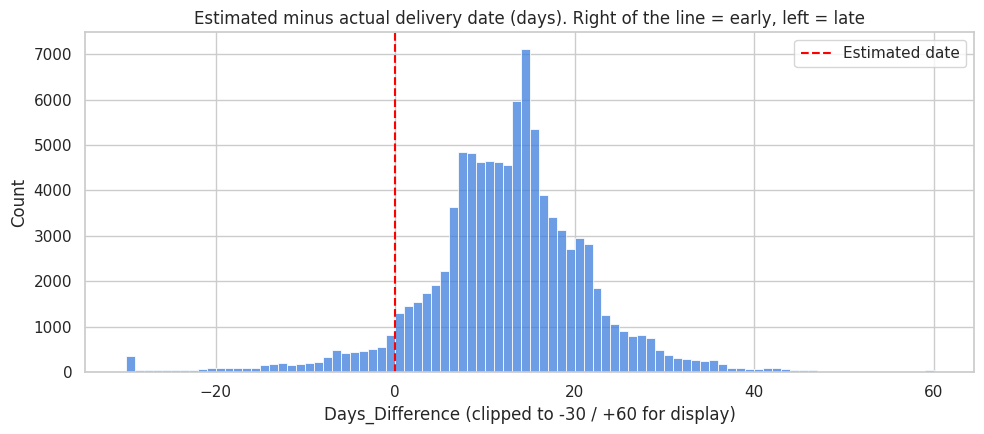

Median Days_Difference: 12.0
Share delivered early or on time: 93.2%


In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(delivered["Days_Difference"].clip(-30, 60), bins=90, ax=ax, color="#3b7ddd")
ax.axvline(0, color="red", linestyle="--", label="Estimated date")
ax.set_title("Estimated minus actual delivery date (days). Right of the line = early, left = late")
ax.set_xlabel("Days_Difference (clipped to -30 / +60 for display)")
ax.legend()
plt.tight_layout()
plt.show()

print("Median Days_Difference:", delivered["Days_Difference"].median())
print("Share delivered early or on time: "
      f"{(~delivered['is_late']).mean():.1%}")

## Story 3: The Geographic View
Percentage of late orders (Late + Super Late) per customer state.

To test whether "remote" states are hit harder, I add two simple proxies:
- the Brazilian macro-region of the state
- the straight-line distance from São Paulo city to the state capital. São Paulo is used as the distribution hub because it is by far Olist's biggest seller and demand base; this is an assumption, not something the dataset states.

In [8]:
state_region = {
    "AC": "North", "AM": "North", "AP": "North", "PA": "North", "RO": "North", "RR": "North", "TO": "North",
    "AL": "Northeast", "BA": "Northeast", "CE": "Northeast", "MA": "Northeast", "PB": "Northeast",
    "PE": "Northeast", "PI": "Northeast", "RN": "Northeast", "SE": "Northeast",
    "DF": "Central-West", "GO": "Central-West", "MS": "Central-West", "MT": "Central-West",
    "ES": "Southeast", "MG": "Southeast", "RJ": "Southeast", "SP": "Southeast",
    "PR": "South", "RS": "South", "SC": "South",
}

# approximate (lat, lon) of each state capital
capital_coords = {
    "AC": (-9.97, -67.81), "AL": (-9.67, -35.74), "AP": (0.03, -51.07), "AM": (-3.12, -60.02),
    "BA": (-12.97, -38.51), "CE": (-3.73, -38.53), "DF": (-15.79, -47.88), "ES": (-20.32, -40.34),
    "GO": (-16.68, -49.25), "MA": (-2.53, -44.30), "MT": (-15.60, -56.10), "MS": (-20.47, -54.62),
    "MG": (-19.92, -43.94), "PA": (-1.46, -48.50), "PB": (-7.12, -34.86), "PR": (-25.43, -49.27),
    "PE": (-8.05, -34.88), "PI": (-5.09, -42.80), "RJ": (-22.91, -43.17), "RN": (-5.79, -35.21),
    "RS": (-30.03, -51.23), "RO": (-8.76, -63.90), "RR": (2.82, -60.67), "SC": (-27.60, -48.55),
    "SP": (-23.55, -46.63), "SE": (-10.91, -37.07), "TO": (-10.18, -48.33),
}

def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi = p2 - p1
    dlmb = np.radians(lon2 - lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlmb / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))

sp_lat, sp_lon = capital_coords["SP"]
distance_km = {s: haversine_km(sp_lat, sp_lon, la, lo) for s, (la, lo) in capital_coords.items()}

In [9]:
state_summary = (
    delivered.groupby("customer_state")
    .agg(
        orders=("order_id", "count"),
        late_orders=("is_late", "sum"),
        super_late_orders=("is_super_late", "sum"),
        avg_review=("review_score", "mean"),
        median_days_diff=("Days_Difference", "median"),
    )
    .reset_index()
)
state_summary["late_pct"] = state_summary["late_orders"] / state_summary["orders"] * 100
state_summary["super_late_pct"] = state_summary["super_late_orders"] / state_summary["orders"] * 100
state_summary["region"] = state_summary["customer_state"].map(state_region)
state_summary["distance_from_sp_km"] = state_summary["customer_state"].map(distance_km)
state_summary = state_summary.sort_values("late_pct", ascending=False).reset_index(drop=True)

nationwide_late_pct = delivered["is_late"].mean() * 100
print(f"Nationwide late %: {nationwide_late_pct:.2f}")
state_summary

Nationwide late %: 6.77


,customer_state,orders,late_orders,super_late_orders,avg_review,median_days_diff,late_pct,super_late_pct,region,distance_from_sp_km
0,AL,397,85,51,3.85,10.00,21.41,12.85,Northeast,"1,928.69"
1,MA,717,125,74,3.83,11.00,17.43,10.32,Northeast,"2,350.73"
2,SE,335,51,39,3.91,13.00,15.22,11.64,Northeast,"1,732.25"
3,PI,476,66,35,3.99,14.00,13.87,7.35,Northeast,"2,093.30"
4,CE,1279,176,131,3.94,13.00,13.76,10.24,Northeast,"2,369.41"
5,RR,41,5,4,3.90,20.00,12.20,9.76,North,"3,302.99"
6,BA,3256,396,247,3.93,12.00,12.16,7.59,Northeast,"1,454.76"
7,RJ,12350,1495,1063,3.97,13.00,12.11,8.61,Southeast,360.62
8,PA,946,106,78,3.91,16.00,11.21,8.25,North,"2,464.55"
9,ES,1995,214,123,4.08,12.00,10.73,6.17,Southeast,741.41


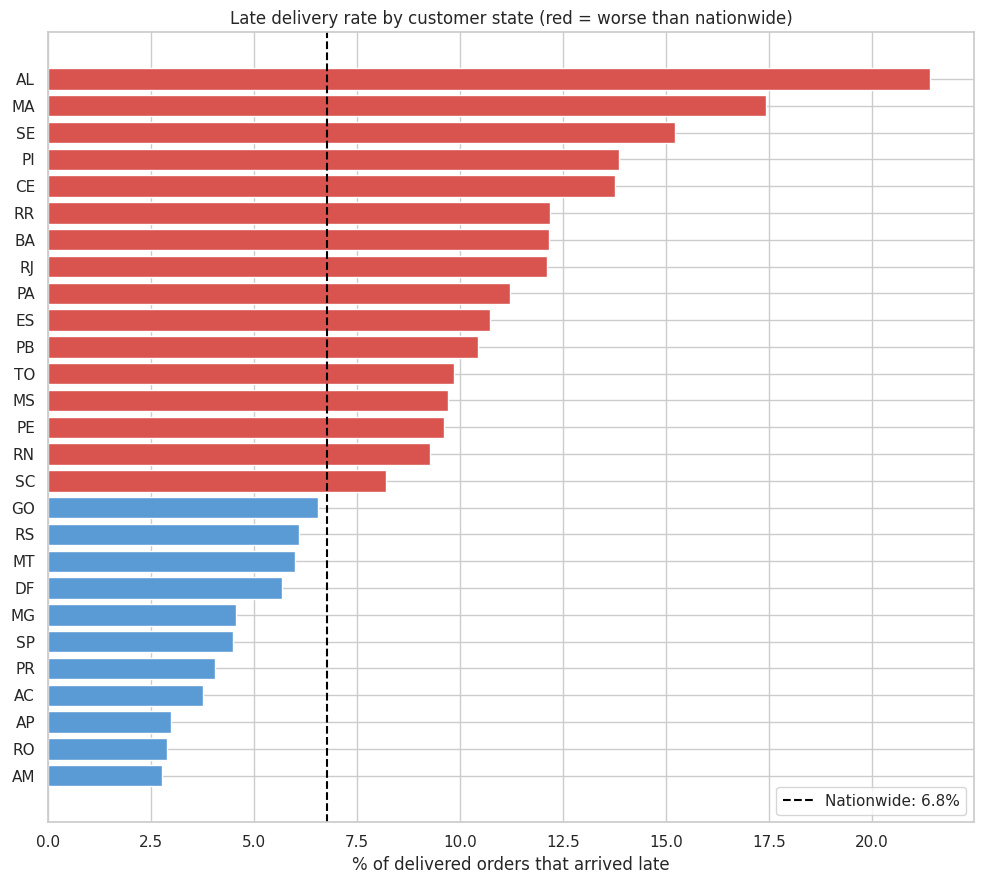

In [10]:
fig, ax = plt.subplots(figsize=(10, 9))
plot_df = state_summary.sort_values("late_pct")
colors = ["#d9534f" if v > nationwide_late_pct else "#5b9bd5" for v in plot_df["late_pct"]]
ax.barh(plot_df["customer_state"], plot_df["late_pct"], color=colors)
ax.axvline(nationwide_late_pct, color="black", linestyle="--", label=f"Nationwide: {nationwide_late_pct:.1f}%")
ax.set_xlabel("% of delivered orders that arrived late")
ax.set_title("Late delivery rate by customer state (red = worse than nationwide)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Is it the remote states?** Late % by macro-region, and the relationship with distance from São Paulo. Small states have few orders, so the order counts are shown next to the rates.

              orders  late_pct  super_late_pct
region                                        
Northeast       9044     12.72            8.24
North           1796      8.57            5.85
Central-West    5624      6.53            3.49
Southeast      66193      6.12            3.41
South          13813      5.90            3.32

Spearman correlation, distance from SP vs late %: 0.06 (across 27 states)


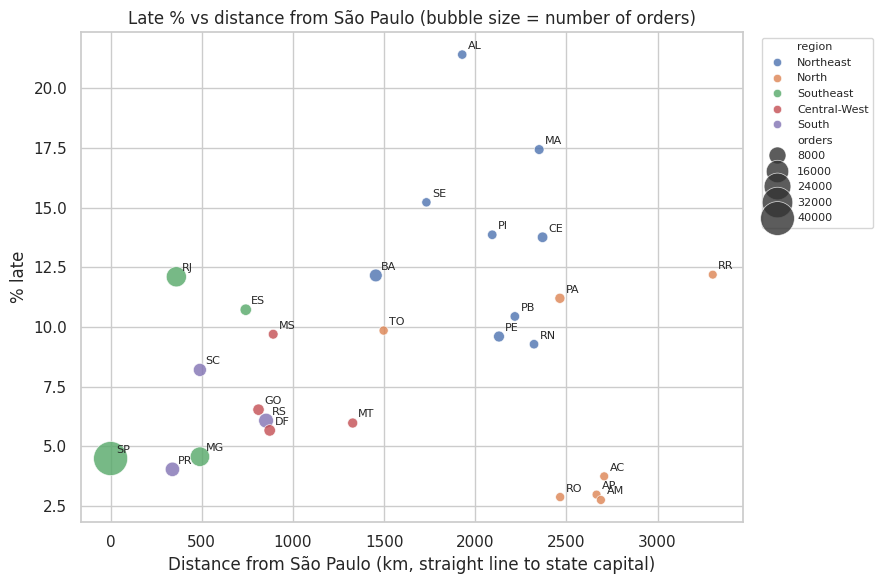

In [11]:
region_summary = (
    delivered.assign(region=delivered["customer_state"].map(state_region))
    .groupby("region")
    .agg(orders=("order_id", "count"), late_pct=("is_late", lambda s: s.mean() * 100),
         super_late_pct=("is_super_late", lambda s: s.mean() * 100))
    .sort_values("late_pct", ascending=False)
)
print(region_summary)

corr = state_summary[["distance_from_sp_km", "late_pct"]].corr(method="spearman").iloc[0, 1]
print(f"\nSpearman correlation, distance from SP vs late %: {corr:.2f} (across {len(state_summary)} states)")

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=state_summary, x="distance_from_sp_km", y="late_pct", size="orders",
                hue="region", sizes=(40, 600), alpha=0.8, ax=ax)
for _, r in state_summary.iterrows():
    ax.annotate(r["customer_state"], (r["distance_from_sp_km"], r["late_pct"]),
                xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("Distance from São Paulo (km, straight line to state capital)")
ax.set_ylabel("% late")
ax.set_title("Late % vs distance from São Paulo (bubble size = number of orders)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## Story 4: The Sentiment Correlation
Do late deliveries lead to worse reviews? Reviews are only available for orders that were actually reviewed, so averages use those rows.

In [12]:
order_of_classes = ["On Time", "Late", "Super Late"]

sentiment = (
    delivered.groupby("delivery_class")
    .agg(orders=("order_id", "count"),
         reviewed=("review_score", "count"),
         avg_review=("review_score", "mean"),
         pct_1_star=("review_score", lambda s: (s == 1).sum() / s.notna().sum() * 100),
         pct_5_star=("review_score", lambda s: (s == 5).sum() / s.notna().sum() * 100))
    .reindex(order_of_classes)
)
sentiment

,orders,reviewed,avg_review,pct_1_star,pct_5_star
delivery_class,,,,,
On Time,89936,89443,4.29,6.62,62.27
Late,2770,2722,2.99,33.61,28.29
Super Late,3764,3659,1.74,68.76,7.79


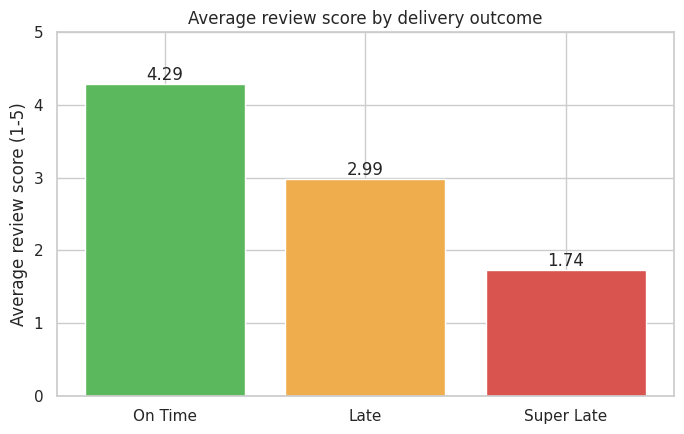

In [13]:
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(sentiment.index, sentiment["avg_review"], color=["#5cb85c", "#f0ad4e", "#d9534f"])
ax.bar_label(bars, fmt="%.2f")
ax.set_ylim(0, 5)
ax.set_ylabel("Average review score (1-5)")
ax.set_title("Average review score by delivery outcome")
plt.tight_layout()
plt.show()

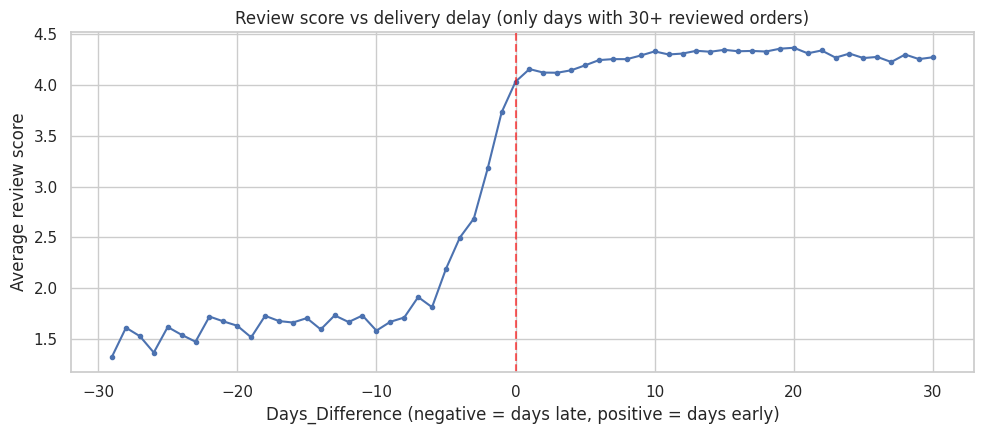

Average review, on time: 4.29
Average review, late (Late + Super Late): 2.27
Difference: 2.02 points
Correlation (Days_Difference vs review_score): 0.27


In [14]:
# review score as a function of the delay itself
by_days = (
    delivered.dropna(subset=["review_score"])
    .groupby("Days_Difference")
    .agg(avg_review=("review_score", "mean"), n=("review_score", "size"))
    .reset_index()
)
by_days = by_days[(by_days["n"] >= 30) & by_days["Days_Difference"].between(-30, 30)]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(by_days["Days_Difference"], by_days["avg_review"], marker="o", markersize=3)
ax.axvline(0, color="red", linestyle="--", alpha=0.6)
ax.set_xlabel("Days_Difference (negative = days late, positive = days early)")
ax.set_ylabel("Average review score")
ax.set_title("Review score vs delivery delay (only days with 30+ reviewed orders)")
plt.tight_layout()
plt.show()

on_time_avg = sentiment.loc["On Time", "avg_review"]
late_avg = delivered.loc[delivered["is_late"], "review_score"].mean()
print(f"Average review, on time: {on_time_avg:.2f}")
print(f"Average review, late (Late + Super Late): {late_avg:.2f}")
print(f"Difference: {on_time_avg - late_avg:.2f} points")
print("Correlation (Days_Difference vs review_score): "
      f"{delivered[['Days_Difference', 'review_score']].corr().iloc[0, 1]:.2f}")

## Bonus: English product categories
Products connect to orders through `order_items`, and one order can contain several categories. For the category analysis I therefore use one row per **distinct (order, category)** pair, so an order with two categories counts once in each. This is kept separate from the master table so the master stays one row per order.

Two categories exist in the products file without a translation, and some products have no category at all. I fall back to the Portuguese name for the first case and label the second "unknown".

In [15]:
prod_cat = products[["product_id", "product_category_name"]].merge(
    translation, on="product_category_name", how="left"
)
prod_cat["category_en"] = (
    prod_cat["product_category_name_english"]
    .fillna(prod_cat["product_category_name"])
    .fillna("unknown")
)

untranslated = prod_cat.loc[
    prod_cat["product_category_name"].notna() & prod_cat["product_category_name_english"].isna(),
    "product_category_name"].unique()
print("Categories without an official translation:", list(untranslated))

order_categories = (
    items[["order_id", "product_id"]]
    .merge(prod_cat[["product_id", "category_en"]], on="product_id", how="left")
    .assign(category_en=lambda d: d["category_en"].fillna("unknown"))
    [["order_id", "category_en"]]
    .drop_duplicates()
)

cat_orders = order_categories.merge(
    delivered[["order_id", "is_late", "is_super_late", "Days_Difference", "review_score"]],
    on="order_id", how="inner",
)

category_summary = (
    cat_orders.groupby("category_en")
    .agg(orders=("order_id", "nunique"),
         late_pct=("is_late", lambda s: s.mean() * 100),
         avg_days_diff=("Days_Difference", "mean"),
         avg_review=("review_score", "mean"))
    .reset_index()
)

MIN_ORDERS = 200  # ignore tiny categories, their percentages are too noisy
cat_big = category_summary[category_summary["orders"] >= MIN_ORDERS].sort_values("late_pct", ascending=False)
cat_big.head(15)

Categories without an official translation: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']


,category_en,orders,late_pct,avg_days_diff,avg_review
4,audio,348,11.78,10.04,3.84
47,home_confort,392,9.44,9.76,3.88
10,books_technical,256,8.20,11.33,4.43
57,office_furniture,1254,8.05,11.82,3.64
6,baby,2809,8.05,11.50,4.10
26,electronics,2517,7.63,11.02,4.12
56,musical_instruments,611,7.53,11.48,4.23
43,health_beauty,8647,7.51,11.98,4.23
40,furniture_living_room,414,7.49,11.73,4.07
7,bed_bath_table,9272,7.43,11.39,4.00


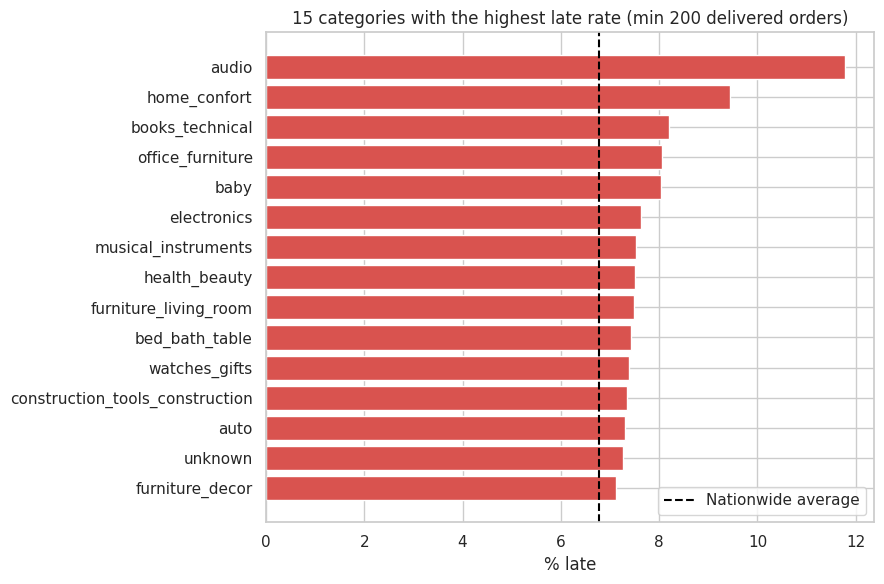

,category_en,orders,late_pct,avg_days_diff,avg_review
39,furniture_decor,6307,7.12,12.34,4.06
26,electronics,2517,7.63,11.02,4.12
57,office_furniture,1254,8.05,11.82,3.64
40,furniture_living_room,414,7.49,11.73,4.07
51,kitchen_dining_laundry_garden_furniture,241,4.56,12.29,4.13
38,furniture_bedroom,90,6.67,13.33,4.26
41,furniture_mattress_and_upholstery,37,13.51,7.16,3.89


In [16]:
top = cat_big.head(15).sort_values("late_pct")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top["category_en"], top["late_pct"], color="#d9534f")
ax.axvline(nationwide_late_pct, color="black", linestyle="--", label="Nationwide average")
ax.set_xlabel("% late")
ax.set_title(f"15 categories with the highest late rate (min {MIN_ORDERS} delivered orders)")
ax.legend()
plt.tight_layout()
plt.show()

# is furniture harder to ship than electronics?
mask = category_summary["category_en"].str.contains("furniture|electronics", case=False, regex=True)
category_summary[mask].sort_values("orders", ascending=False)

## Candidate's Choice: Promised vs actual lead time by state
**What:** for each state, the median number of days we *promised* (estimated date minus purchase date) next to the median number of days it *actually took* (delivery date minus purchase date), plus the "padding" between them and the late %.

**Why it matters:** the CEO's question is whether the estimates themselves are wrong. This separates two different problems that need different fixes:
- states where the promise is much longer than reality have padded estimates, yet may still have a late tail (the fix is carrier or last-mile operations)
- states where the promise is only a little longer than reality have tight estimates (the fix is to recalibrate the ETA shown at checkout)

In [17]:
delivered["promised_days"] = (delivered["estimated_date"] - delivered["purchase_date"]).dt.days
delivered["actual_days"] = (delivered["delivered_date"] - delivered["purchase_date"]).dt.days

lead = (
    delivered.groupby("customer_state")
    .agg(orders=("order_id", "count"),
         median_promised_days=("promised_days", "median"),
         median_actual_days=("actual_days", "median"),
         late_pct=("is_late", lambda s: s.mean() * 100))
    .reset_index()
)
lead["median_padding_days"] = lead["median_promised_days"] - lead["median_actual_days"]
lead = lead.sort_values("median_promised_days", ascending=False).reset_index(drop=True)
lead

,customer_state,orders,median_promised_days,median_actual_days,late_pct,median_padding_days
0,AP,67,48.00,25.00,2.99,23.00
1,AM,145,46.00,26.00,2.76,20.00
2,RR,41,45.00,25.00,12.20,20.00
3,AC,80,41.00,18.00,3.75,23.00
4,RO,243,38.00,18.00,2.88,20.00
5,PA,946,37.00,21.00,11.21,16.00
6,PB,517,33.00,18.00,10.44,15.00
7,RN,474,32.50,16.00,9.28,16.50
8,AL,397,32.00,22.00,21.41,10.00
9,MT,886,32.00,16.00,5.98,16.00


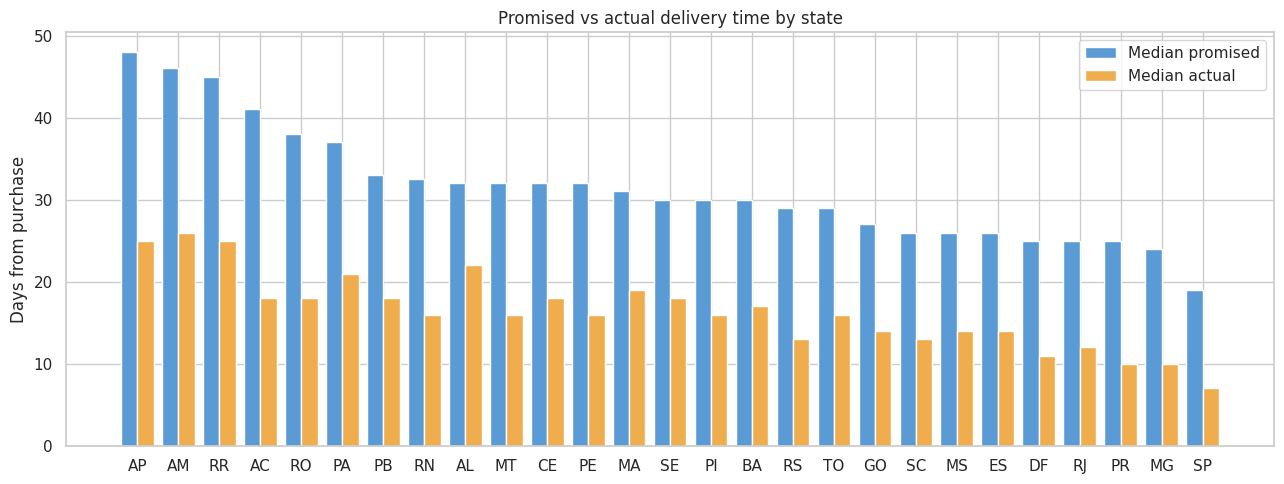

In [18]:
plot_lead = lead.sort_values("median_promised_days", ascending=False)
x = np.arange(len(plot_lead))
w = 0.4
fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(x - w / 2, plot_lead["median_promised_days"], w, label="Median promised", color="#5b9bd5")
ax.bar(x + w / 2, plot_lead["median_actual_days"], w, label="Median actual", color="#f0ad4e")
ax.set_xticks(x)
ax.set_xticklabels(plot_lead["customer_state"])
ax.set_ylabel("Days from purchase")
ax.set_title("Promised vs actual delivery time by state")
ax.legend()
plt.tight_layout()
plt.show()

## Export slim data for the dashboard
Only the columns the dashboard needs (no raw CSVs), so the repo stays small.

In [19]:
out_dir = Path("dashboard_data")
out_dir.mkdir(exist_ok=True)

slim = delivered[[
    "order_id", "customer_state", "purchase_date", "delivered_date", "estimated_date",
    "Days_Difference", "delivery_class", "is_late", "is_super_late", "review_score",
    "promised_days", "actual_days",
]].copy()
slim["region"] = slim["customer_state"].map(state_region)

slim.to_csv(out_dir / "orders_slim.csv", index=False)
state_summary.to_csv(out_dir / "state_summary.csv", index=False)
lead.to_csv(out_dir / "lead_time_by_state.csv", index=False)
category_summary.to_csv(out_dir / "category_summary.csv", index=False)
sentiment.reset_index().to_csv(out_dir / "sentiment_by_class.csv", index=False)

for f in sorted(out_dir.iterdir()):
    print(f"{f.name:28s} {f.stat().st_size / 1024:,.0f} KB")

category_summary.csv         5 KB
lead_time_by_state.csv       1 KB
orders_slim.csv              10,616 KB
sentiment_by_class.csv       0 KB
state_summary.csv            3 KB


In [20]:
import os
print(os.getcwd())
print(os.listdir("."))

/content
['.config', 'olist_order_reviews_dataset.csv', 'olist_products_dataset.csv', 'olist_order_items_dataset.csv', 'olist_orders_dataset.csv', 'dashboard_data', 'product_category_name_translation.csv', 'olist_customers_dataset.csv', 'sample_data']


In [21]:
import os
print(os.listdir("dashboard_data"))
for f in sorted(os.listdir("dashboard_data")):
    print(f, round(os.path.getsize(os.path.join("dashboard_data", f)) / 1024), "KB")

!zip -r dashboard_data.zip dashboard_data

from google.colab import files
files.download("dashboard_data.zip")

['sentiment_by_class.csv', 'category_summary.csv', 'orders_slim.csv', 'state_summary.csv', 'lead_time_by_state.csv']
category_summary.csv 5 KB
lead_time_by_state.csv 1 KB
orders_slim.csv 10616 KB
sentiment_by_class.csv 0 KB
state_summary.csv 3 KB
  adding: dashboard_data/ (stored 0%)
  adding: dashboard_data/sentiment_by_class.csv (deflated 30%)
  adding: dashboard_data/category_summary.csv (deflated 51%)
  adding: dashboard_data/orders_slim.csv (deflated 69%)
  adding: dashboard_data/state_summary.csv (deflated 48%)
  adding: dashboard_data/lead_time_by_state.csv (deflated 49%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>